# Linear versus ResNet classification heads on whole-cell windows

Compare **10-node, soma-restricted CAVE windows** from whole cells, using mean pooling, a two-layer skeleton MPNN with LPE and center-relative position, the full four-layer GT with LPE/relative position/adjacency bias, and a two-layer pointwise MLP. Each aggregator is paired with either linear LCPN branch classifiers or a shared **4 × 128 ResNet** followed by those classifiers.

**Nothing is frozen.** All learned aggregator and decoder weights train together. Raw mean pooling has no learned parameters. “Linear” refers to the classification head, not the separate `architecture=linear` node encoder. Hierarchical routing also means the linear-head model is not a single flat multinomial regression.

Historical ResNet reports are reused; new linear-head runs match their 16 epochs, batch size 4096, learning rate 1e-4, weight decay 1e-5, seed 0, class-balanced sampling, labels and split. The models train from scratch. Mean and pointwise MLP consume embeddings only; the graph methods retain their normal geometry inputs. Head comparisons are matched **within each aggregator**.

The nucleus-centered **5 µm Euclidean exclusion** cuts the skeleton before defining windows. Cells without nucleus positions remain uncut, matching the historical runs. The original eight classes include glia and the earlier interneuron labels; this is not the newer six-class Morpho experiment.

These are **one 80/20 cell-held-out split, not five-fold CV**. The original trainer selects the best window macro-F1 checkpoint on this same held-out split, so these are model-selection scores, not an untouched final test estimate. Windows from one cell are correlated. Cell metrics use majority vote over windows; no cross-fold confidence intervals are claimed. Whether ResNet helps more for mean pooling is a hypothesis to assess from the completed pairs, not an assumption.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from IPython.display import display
import matplotlib.pyplot as plt
root = Path.cwd().resolve()
while not (root / 'scripts/train_gnn.py').exists():
    if root == root.parent: raise RuntimeError('Run inside the repository')
    root = root.parent
sys.path.insert(0, str(root / 'analysis/all_windows/linear_vs_resnet'))
import comparison
cache = comparison.refresh_cache()  # reads cached reports/CSV only; no inference
scores = comparison.table(cache)
display(scores.round(4))

,architecture,head,complete,epochs_available,window_balanced_accuracy,window_macro_precision,window_macro_f1,cell_balanced_accuracy,cell_macro_precision,cell_macro_f1
0,Mean,Linear,True,16,0.6767,0.5911,0.6133,0.8405,0.9390,0.8801
1,Mean,ResNet,True,16,0.8296,0.8124,0.8188,0.9098,0.9724,0.9359
2,MPNN L2 + LPE + relative position,Linear,True,16,0.8471,0.8139,0.8281,0.9590,0.9700,0.9640
3,MPNN L2 + LPE + relative position,ResNet,True,16,0.8491,0.8343,0.8379,0.9493,0.9679,0.9557
4,GT L4 + LPE + relative position,Linear,True,16,0.8362,0.8441,0.8368,0.9190,0.9779,0.9431
5,GT L4 + LPE + relative position,ResNet,True,16,0.8420,0.8443,0.8397,0.9590,0.9700,0.9640
6,Pointwise MLP L2,Linear,True,16,0.8262,0.8044,0.8134,0.9098,0.9640,0.9315
7,Pointwise MLP L2,ResNet,True,16,0.8438,0.8243,0.8310,0.9683,0.9795,0.9734


## Window and cell performance

Missing bars indicate an unfinished run. Window balanced accuracy, macro precision and macro F1 are shown above the corresponding cell scores.

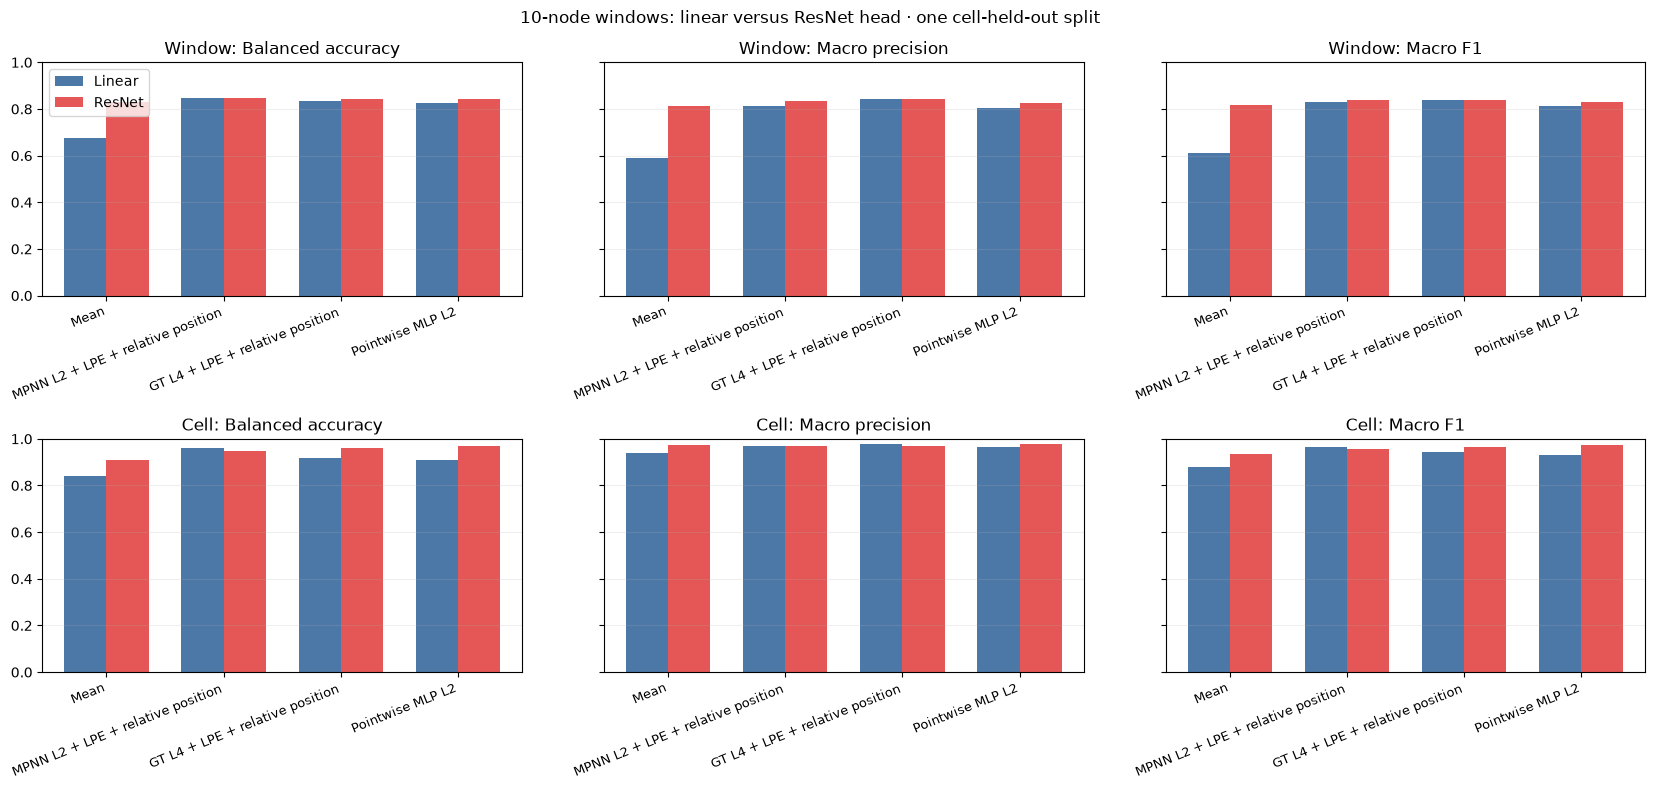

In [2]:
comparison.score_plot(cache); plt.show()

## ResNet benefit within each aggregator

Positive differences favor the ResNet head. Compare the mean-pooling difference with those of learned aggregators to assess the proposed narrative. Differences remain missing until both paired reports exist.

,window_balanced_accuracy,window_macro_precision,window_macro_f1,cell_balanced_accuracy,cell_macro_precision,cell_macro_f1
ResNet minus linear,,,,,,
Mean,0.1530,0.2212,0.2054,0.0693,0.0334,0.0558
MPNN L2 + LPE + relative position,0.0019,0.0204,0.0099,-0.0097,-0.0021,-0.0083
GT L4 + LPE + relative position,0.0058,0.0002,0.0029,0.0400,-0.0078,0.0209
Pointwise MLP L2,0.0176,0.0199,0.0176,0.0585,0.0155,0.0419


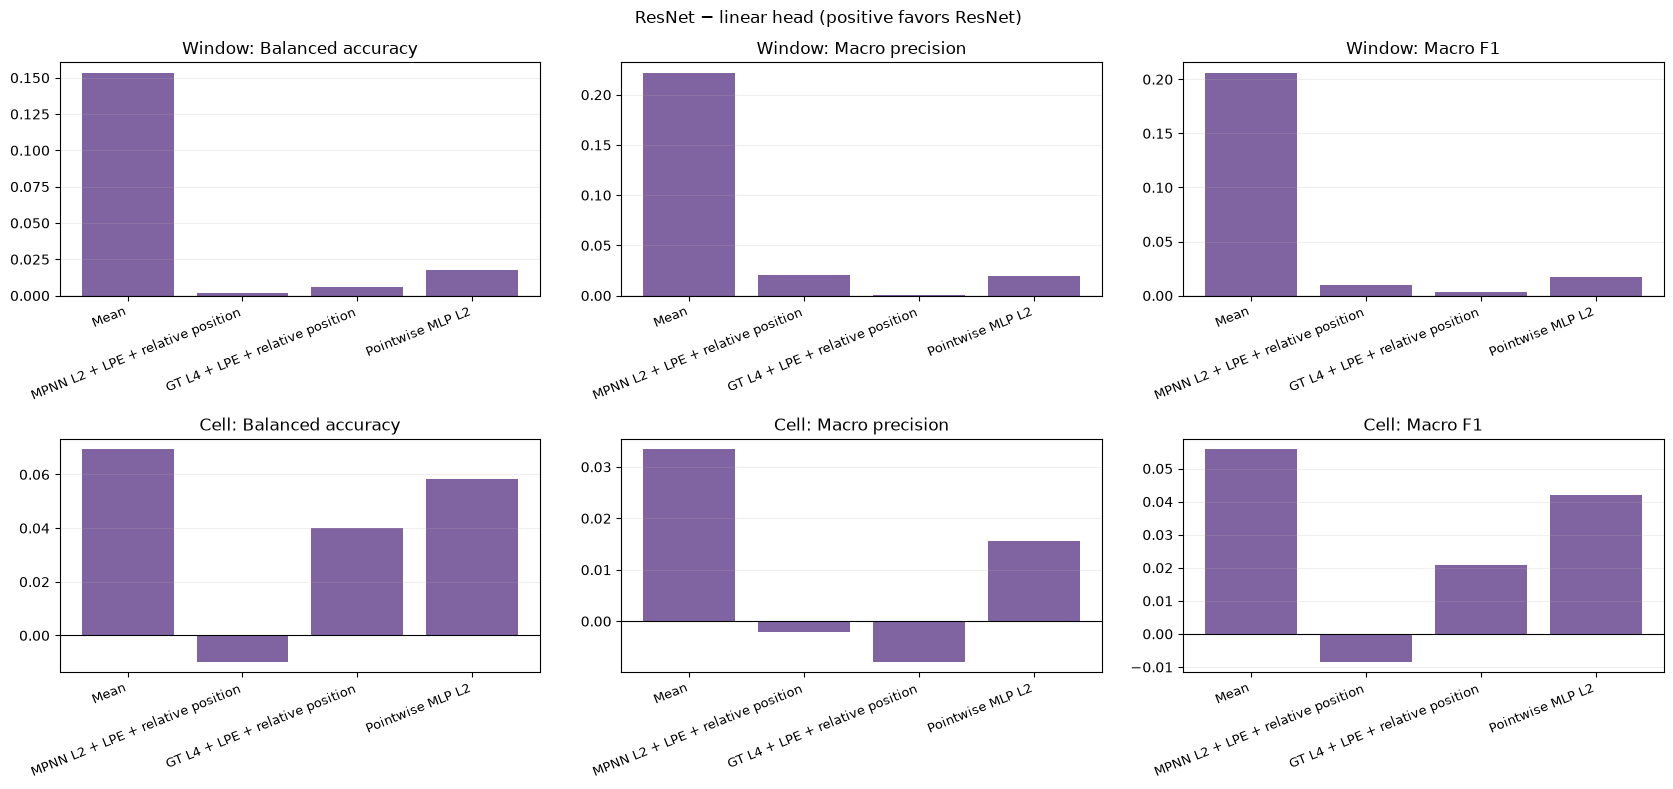

In [3]:
metrics = [f'{s}_{m}' for s in ('window', 'cell') for m in comparison.METRICS]
linear = scores[scores['head'] == 'Linear'].set_index('architecture')[metrics]
resnet = scores[scores['head'] == 'ResNet'].set_index('architecture')[metrics]
display((resnet - linear).round(4).rename_axis('ResNet minus linear'))
comparison.score_plot(cache, difference=True); plt.show()

## Learning curves
Held-out window macro F1 during the 16 training epochs. These curves expose convergence differences that a best-checkpoint score alone can hide.

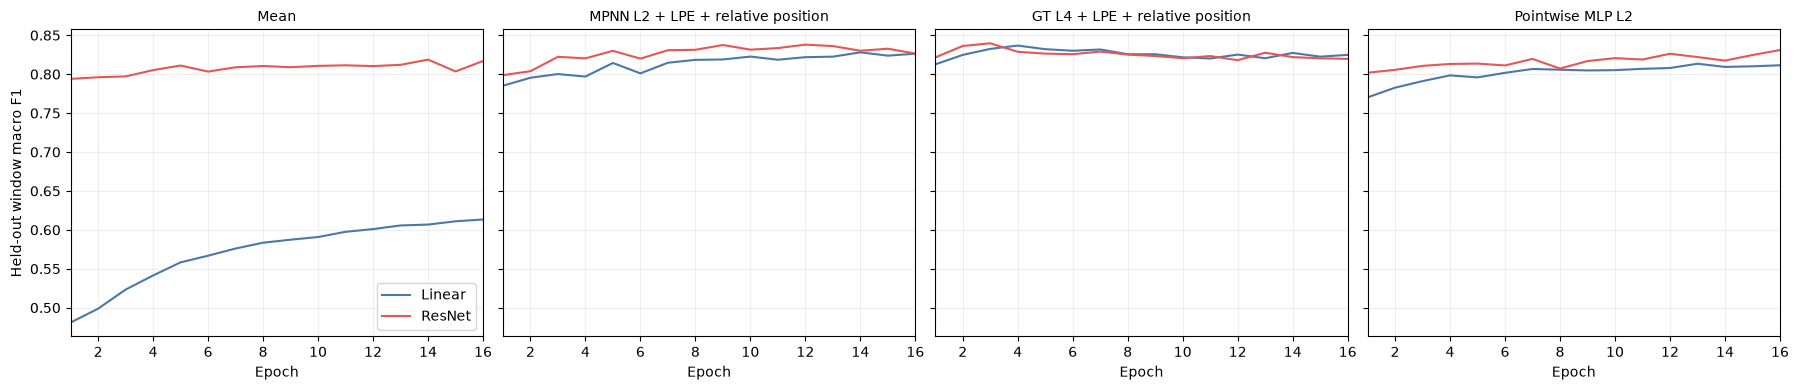

In [4]:
comparison.learning_curves(cache); plt.show()

## Window confusion matrices

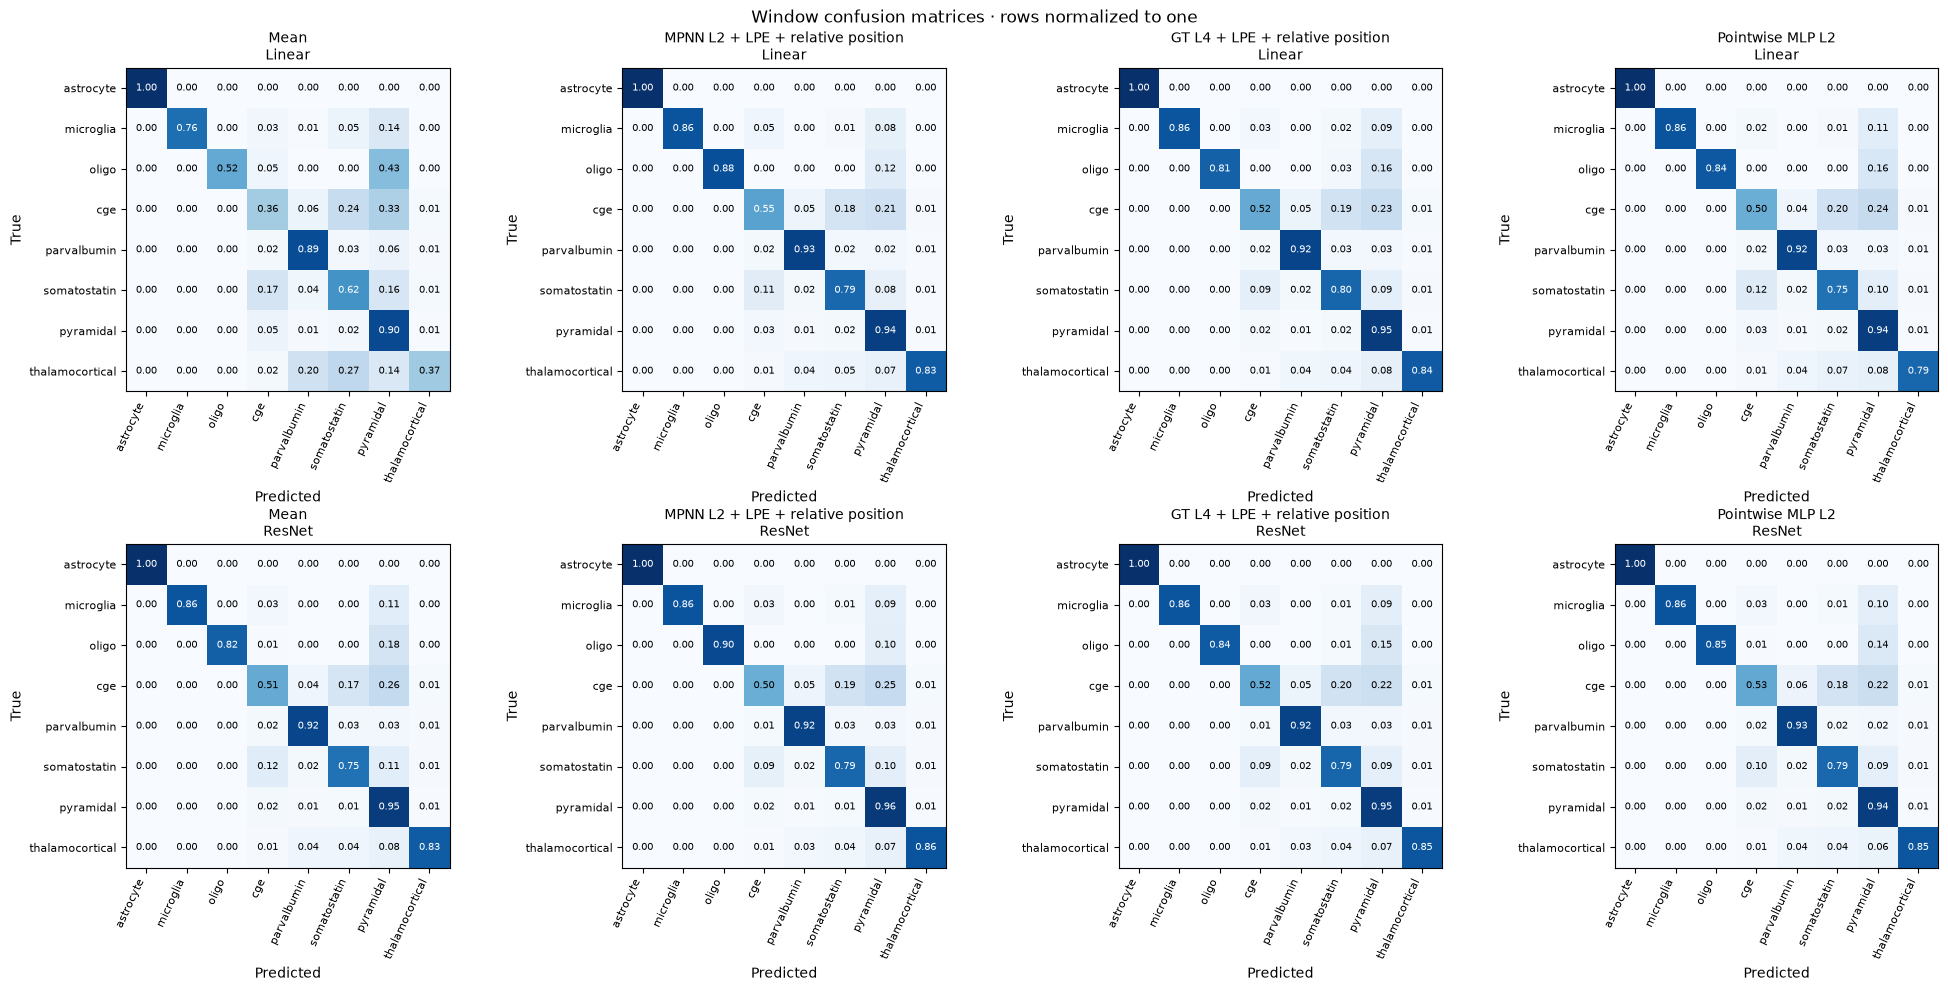

In [5]:
comparison.confusions(cache, 'window'); plt.show()

## Cell confusion matrices

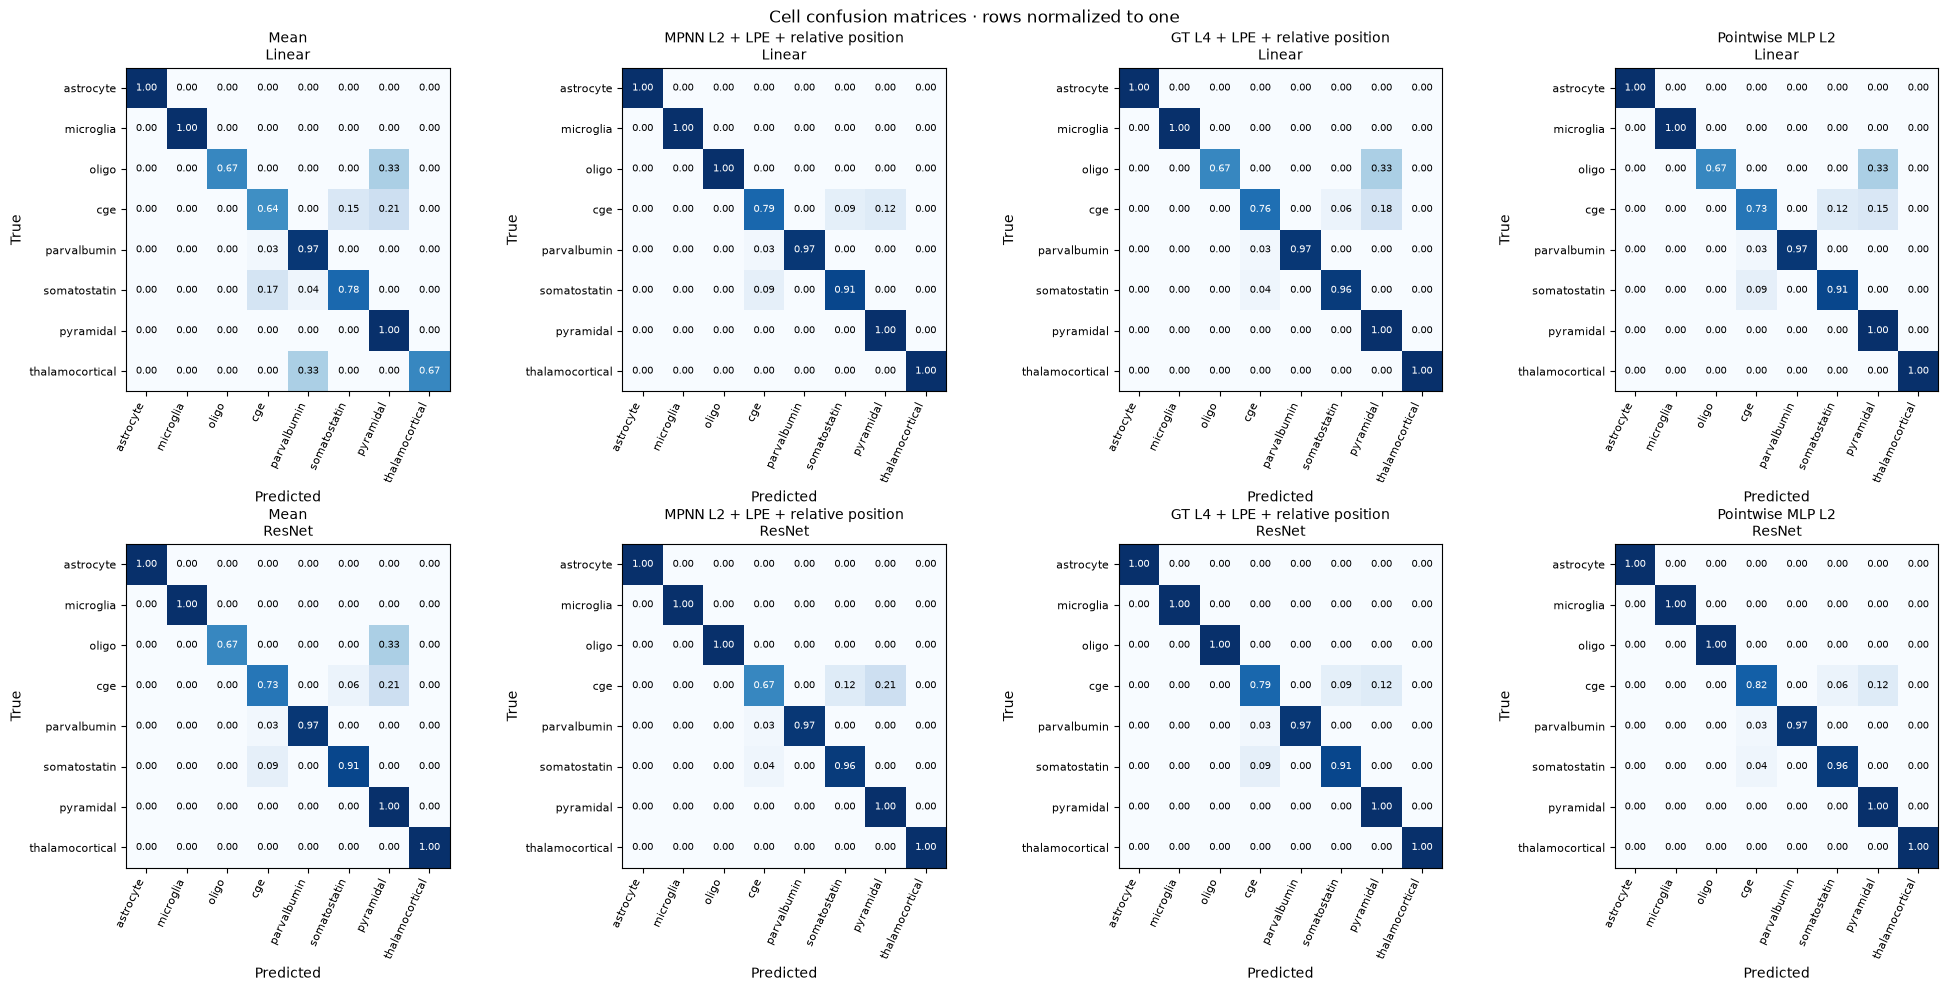

In [6]:
comparison.confusions(cache, 'cell'); plt.show()

## Provenance and soma-exclusion audit

`linear_vs_resnet/plan.json` records source report hashes and paired configurations; `manifest.json` freezes labels, hierarchy and cell splits. `preflight.json` verifies the historical per-class test support against the current membership cache and records roots with no soma cut. `report_cache.json` is a small regenerable snapshot of metrics and curves, not embeddings. Training uses the existing graph and neighborhood caches and publishes per-window predictions through the standard prediction-cache writer.

In [7]:
import json
audit_path = comparison.BASE / 'preflight.json'
if audit_path.exists():
    audit = json.loads(audit_path.read_text())
    display({k:v for k,v in audit.items() if k != 'roots'})
else:
    print('Preflight audit pending')
display(scores[['architecture','head','complete','epochs_available']])

{'classes': ['astrocyte',
  'microglia',
  'oligo',
  'putative_cge',
  'putative_parvalbumin',
  'putative_somatostatin',
  'pyramidal',
  'thalamocortical'],
 'test_class_windows': [24825,
  3318,
  919,
  146808,
  403139,
  182333,
  1627553,
  34255],
 'splits': {'train': {'cells': 1866, 'windows': 9702190},
  'test': {'cells': 466, 'windows': 2423150}},
 'uncut_roots': [864691134800773453,
  864691135386365313,
  864691135454214130,
  864691135494051472,
  864691135544366632,
  864691135588675012,
  864691135593907263,
  864691135908742552,
  864691135920665264,
  864691136086328195,
  864691136324937182,
  864691136715774812,
  864691136723466749,
  864691135476145832,
  864691135620793284,
  864691135772065787],
 'missing_membership_roots': [],
 'matched_historical_test_support': True}

,architecture,head,complete,epochs_available
0,Mean,Linear,True,16
1,Mean,ResNet,True,16
2,MPNN L2 + LPE + relative position,Linear,True,16
3,MPNN L2 + LPE + relative position,ResNet,True,16
4,GT L4 + LPE + relative position,Linear,True,16
5,GT L4 + LPE + relative position,ResNet,True,16
6,Pointwise MLP L2,Linear,True,16
7,Pointwise MLP L2,ResNet,True,16
